In [1]:
%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from dataset import ShapeDataset
from torch.utils.data import DataLoader
from model import Model
from torchinfo import summary
import torch.optim as optim
import torch.nn as nn
import torch
import numpy as np

train_set = ShapeDataset(size=1000, seed=0)
test_set = ShapeDataset(size=200, seed=1)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
images, masks = next(iter(train_loader))
print(f"train: {len(train_set)}, test: {len(test_set)}")
print(f"batch: images {images.shape}, masks {masks.shape}")

train: 1000, test: 200
batch: images torch.Size([16, 1, 128, 128]), masks torch.Size([16, 1, 128, 128])


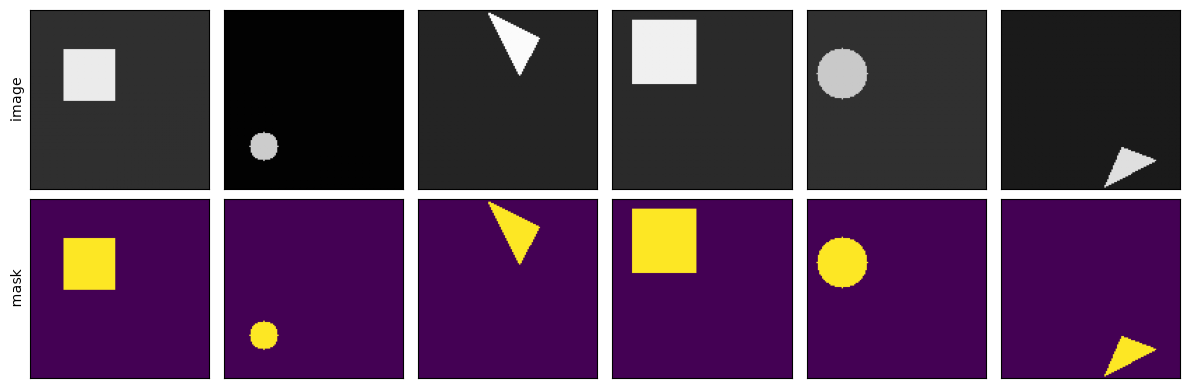

In [2]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    image, mask = train_set[i]
    axes[0, i].imshow(image[0, :, :], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(mask[0, :, :], cmap="viridis", vmin=0, vmax=1)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("image")
axes[1, 0].set_ylabel("mask")
plt.tight_layout()
plt.show()

In [3]:
model = Model()
print(model)
summary(model, input_size=(1, 1, 128, 128))

Model(
  (ds1): DownsamplingBlock(
    (conv): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu): ReLU()
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (ds2): DownsamplingBlock(
    (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu): ReLU()
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bottleneck): BottleneckBlock(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu): ReLU()
  )
  (us1): UpsamplingBlock(
    (upconv): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
    (conv): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu): ReLU()
  )
  (us2): UpsamplingBlock(
    (upconv): ConvTranspose2d(32, 16, kernel_size=(2, 2), stride=(2, 2))
    (conv): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu): ReLU()
  )
  (output_conv): Conv2d(16, 

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [1, 1, 128, 128]          --
├─DownsamplingBlock: 1-1                 [1, 16, 64, 64]           --
│    └─Conv2d: 2-1                       [1, 16, 128, 128]         160
│    └─ReLU: 2-2                         [1, 16, 128, 128]         --
│    └─MaxPool2d: 2-3                    [1, 16, 64, 64]           --
├─DownsamplingBlock: 1-2                 [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 32, 64, 64]           4,640
│    └─ReLU: 2-5                         [1, 32, 64, 64]           --
│    └─MaxPool2d: 2-6                    [1, 32, 32, 32]           --
├─BottleneckBlock: 1-3                   [1, 64, 32, 32]           --
│    └─Conv2d: 2-7                       [1, 64, 32, 32]           18,496
│    └─ReLU: 2-8                         [1, 64, 32, 32]           --
├─UpsamplingBlock: 1-4                   [1, 32, 64, 64]           --
│    └─

In [4]:
criterion = nn.BCELoss()
optimizer = optim.AdamW(model.parameters(), weight_decay=0.01)

epochs = 10
history = {
    "update_loss": [],
    "loss": [],
    "val_loss": [],
    "tp": [],
    "fp": [],
    "tn": [],
    "fn": [],
    "accuracy": [],
    "iou": [],
}

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_hat = model(X_batch)
        loss = criterion(y_hat, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
        history["update_loss"].append(loss.item())
    history["loss"].append(running_loss / len(train_set))

    model.eval()
    with torch.no_grad():
        y_hat = model(test_set.images)
        history["val_loss"].append(criterion(y_hat, test_set.masks).item())

        predicted = y_hat > 0.5
        actual = test_set.masks.bool()
        tp = (predicted & actual).sum().item()
        fp = (predicted & ~actual).sum().item()
        tn = (~predicted & ~actual).sum().item()
        fn = (~predicted & actual).sum().item()

    history["tp"].append(tp)
    history["fp"].append(fp)
    history["tn"].append(tn)
    history["fn"].append(fn)
    history["accuracy"].append((tp + tn) / (tp + fp + tn + fn))
    history["iou"].append(tp / (tp + fp + fn))

    print(
        f"Epoch {epoch + 1}: "
        f"loss {history['loss'][-1]:.4f}, val_loss {history['val_loss'][-1]:.4f}, "
        f"accuracy {history['accuracy'][-1]:.4f}, iou {history['iou'][-1]:.4f}, "
        f"tp {tp}, fp {fp}, tn {tn}, fn {fn}"
    )

Epoch 1: loss 0.2004, val_loss 0.0090, accuracy 0.9970, iou 0.9543, tp 204758, fp 4901, tn 3062244, fn 4897


Epoch 2: loss 0.0053, val_loss 0.0030, accuracy 0.9991, iou 0.9859, tp 208968, fp 2296, tn 3064849, fn 687


Epoch 3: loss 0.0021, val_loss 0.0015, accuracy 0.9995, iou 0.9927, tp 209336, fp 1216, tn 3065929, fn 319


Epoch 4: loss 0.0011, val_loss 0.0007, accuracy 0.9998, iou 0.9971, tp 209246, fp 193, tn 3066952, fn 409


Epoch 5: loss 0.0006, val_loss 0.0005, accuracy 0.9999, iou 0.9982, tp 209351, fp 83, tn 3067062, fn 304


Epoch 6: loss 0.0004, val_loss 0.0004, accuracy 0.9999, iou 0.9986, tp 209377, fp 26, tn 3067119, fn 278


Epoch 7: loss 0.0003, val_loss 0.0002, accuracy 1.0000, iou 0.9992, tp 209514, fp 19, tn 3067126, fn 141


Epoch 8: loss 0.0002, val_loss 0.0002, accuracy 1.0000, iou 0.9997, tp 209631, fp 33, tn 3067112, fn 24


Epoch 9: loss 0.0002, val_loss 0.0001, accuracy 1.0000, iou 0.9998, tp 209631, fp 9, tn 3067136, fn 24


Epoch 10: loss 0.0001, val_loss 0.0001, accuracy 1.0000, iou 0.9999, tp 209645, fp 3, tn 3067142, fn 10


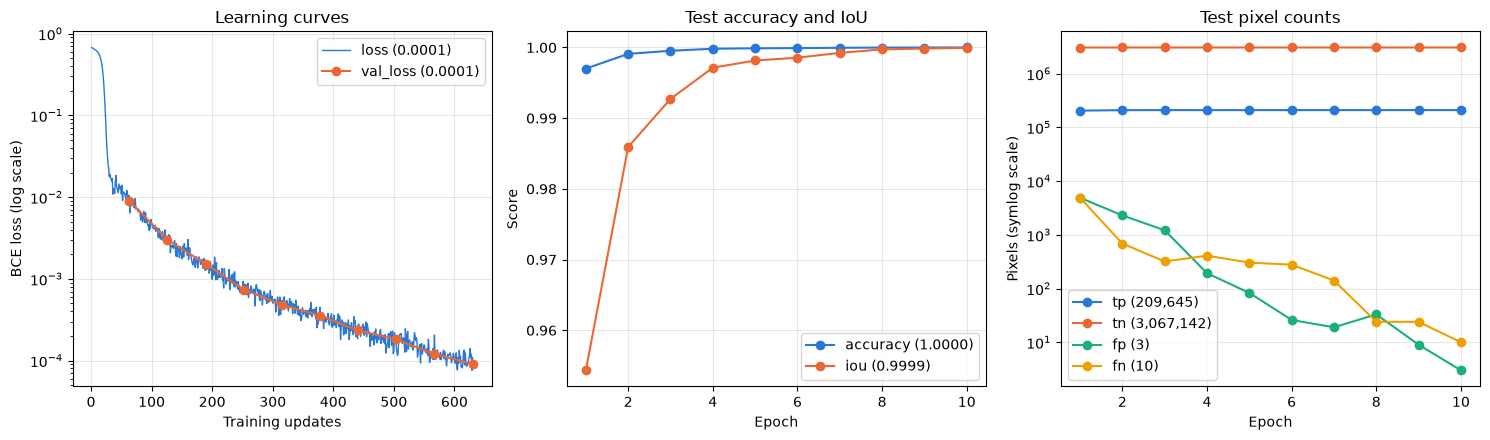

In [5]:
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
)

fig, (ax_loss, ax_metrics, ax_counts) = plt.subplots(1, 3, figsize=(15, 4.5))
epoch_range = range(1, epochs + 1)

ax_loss.plot(
    range(1, len(history["update_loss"]) + 1),
    history["update_loss"],
    linewidth=1,
    label=f"loss ({history['loss'][-1]:.4f})",
)
ax_loss.plot(
    [epoch * len(train_loader) for epoch in epoch_range],
    history["val_loss"],
    marker="o",
    label=f"val_loss ({history['val_loss'][-1]:.4f})",
)
ax_loss.set_title("Learning curves")
ax_loss.set_xlabel("Training updates")
ax_loss.set_ylabel("BCE loss (log scale)")
ax_loss.set_yscale("log")

for name in ("accuracy", "iou"):
    ax_metrics.plot(
        epoch_range, history[name], marker="o", label=f"{name} ({history[name][-1]:.4f})"
    )
ax_metrics.set_title("Test accuracy and IoU")
ax_metrics.set_xlabel("Epoch")
ax_metrics.set_ylabel("Score")

for name in ("tp", "tn", "fp", "fn"):
    ax_counts.plot(
        epoch_range, history[name], marker="o", label=f"{name} ({history[name][-1]:,})"
    )
ax_counts.set_title("Test pixel counts")
ax_counts.set_xlabel("Epoch")
ax_counts.set_ylabel("Pixels (symlog scale)")
ax_counts.set_yscale("symlog", linthresh=1)

for ax in (ax_loss, ax_metrics, ax_counts):
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()